# 从零实现 DDPM：用 PyTorch 在 MNIST 上生成手写数字

本 Notebook 会从数学公式出发，逐步实现一个小型 **Denoising Diffusion Probabilistic Model (DDPM)**。

完成后，你将能够：
1. 加载并归一化 MNIST；
2. 实现前向扩散过程，直接构造任意噪声时间步的图片；
3. 编写带时间步嵌入的轻量 U-Net；
4. 使用噪声预测损失训练模型；
5. 从随机噪声开始，逐步反向去噪生成数字；
6. 保存模型并查看生成结果。

**建议运行环境：** PyTorch、torchvision、matplotlib。可使用 CPU、Apple Silicon 的 MPS，或 NVIDIA CUDA。首次运行会下载 MNIST。

> 训练时间取决于设备。先用较少 epoch 验证完整流程，再增加训练轮数。这里为了方便学习，使用一个小型 U-Net 和线性噪声调度；生成质量不一定达到大型扩散模型的水平。

## 0. 导入依赖并选择设备

如果 `torchvision` 导入失败，请检查它是否与当前 PyTorch 版本兼容。Apple Silicon Mac 可以尝试使用 MPS；如果 MPS 不可用，代码会回退到 CPU。

In [2]:
import math
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

PyTorch: 2.2.2
Torchvision: 0.17.2
Using device: mps


## 1. 加载 MNIST

`ToTensor()` 将像素缩放到 `[0, 1]`。随后使用 `Normalize((0.5,), (0.5,))` 把范围转换为 `[-1, 1]`，这通常更适合图像生成模型训练。

一个 batch 的形状是 `[B, 1, 28, 28]`：
- `B`：batch size；
- `1`：灰度通道；
- `28 × 28`：图像高度和宽度。

In [3]:
batch_size = 128

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))
print("Images:", images.shape)
print("Labels:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())

Images: torch.Size([128, 1, 28, 28])
Labels: torch.Size([128])
Pixel range: -1.0 1.0


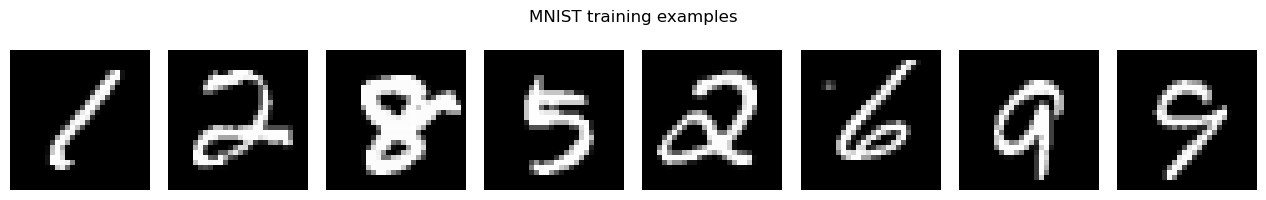

In [4]:
def show_images(images, n=8, title=None):
    images = images.detach().cpu()[:n]
    fig, axes = plt.subplots(1, len(images), figsize=(1.6 * len(images), 2))
    if len(images) == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        # 把 [-1, 1] 转回 [0, 1] 仅用于显示
        img = (images[i, 0] * 0.5 + 0.5).clamp(0, 1)
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_images(images, title="MNIST training examples")

## 2. 前向扩散：逐步添加高斯噪声

DDPM 定义每一步的噪声强度为 \(\beta_t\)，并令 \(\alpha_t=1-\beta_t\)。前向一步转移为

\[
q(x_t\mid x_{t-1})=\mathcal{N}(\sqrt{\alpha_t}x_{t-1},\,\beta_t I).
\]

定义累积乘积

\[
\bar{\alpha}_t=\prod_{s=1}^{t}\alpha_s,
\]

可以推导出直接加噪公式：

\[
\boxed{x_t=\sqrt{\bar{\alpha}_t}x_0+
\sqrt{1-\bar{\alpha}_t}\epsilon,\quad \epsilon\sim\mathcal N(0,I)}
\]

这很重要：训练时不必从 \(x_0\) 一步步加噪到 \(x_t\)，而是可以一次计算直接采样任意时间步。

In [5]:
# 为了让教学实验较快完成，先使用 300 个扩散步。
# 经典 DDPM 常使用 1000 步；稍后可以把 T 改成 1000 进行对比。
T = 300

beta = torch.linspace(1e-4, 0.02, T)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

print("beta shape:", beta.shape)
print("alpha_bar[0]:", alpha_bar[0].item())
print("alpha_bar[-1]:", alpha_bar[-1].item())

beta shape: torch.Size([300])
alpha_bar[0]: 0.9998999834060669
alpha_bar[-1]: 0.04805843159556389


In [6]:
def q_sample(x0, t, noise=None):
    """直接从原图 x0 构造时间步 t 的带噪图像。

    x0: [B, 1, 28, 28]
    t:  [B]，整数索引，范围 0 到 T-1
    返回: xt 和实际添加的 noise
    """
    if noise is None:
        noise = torch.randn_like(x0)

    # 取出每张图片对应的 alpha_bar_t，再 reshape 以便广播
    alpha_bar_t = alpha_bar.to(x0.device)[t].view(-1, 1, 1, 1)

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        + torch.sqrt(1.0 - alpha_bar_t) * noise
    )
    return xt, noise

### 2.1 可视化噪声逐渐增加

每一行显示同一批原图在不同噪声强度下的结果。不同时间步的噪声是分别采样的，因此每行不一定对应同一条随机噪声轨迹。

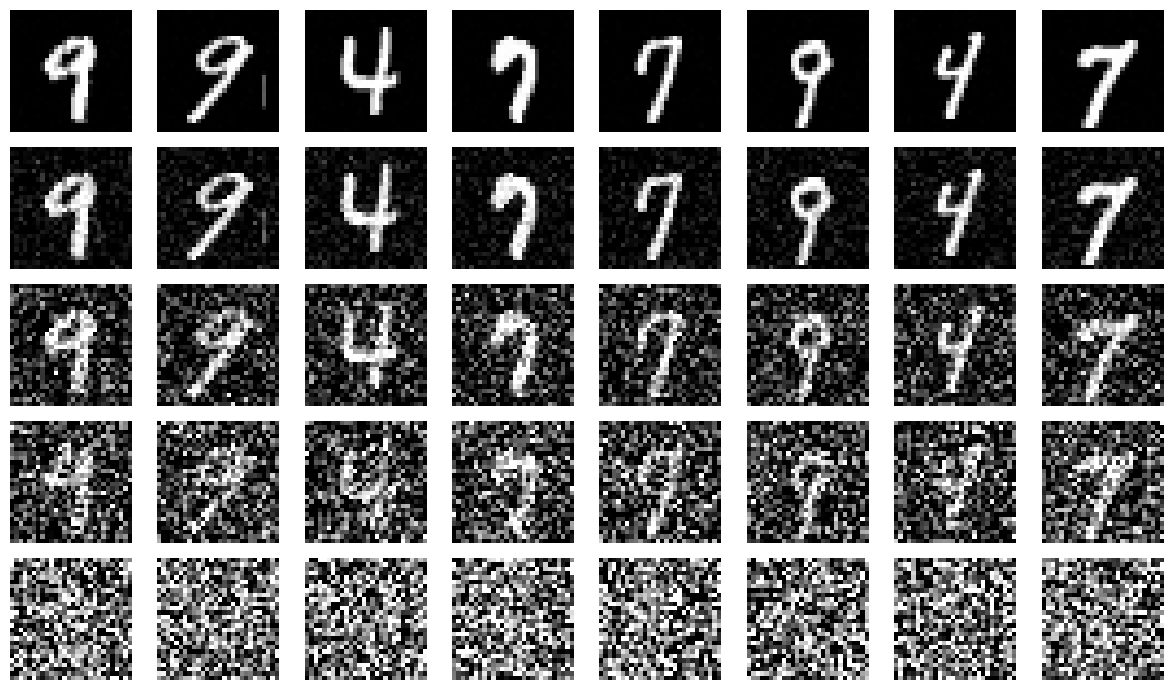

In [7]:
x0, _ = next(iter(train_loader))
x0 = x0[:8].to(device)

time_values = [0, T // 10, T // 3, T // 2, T - 1]
fig, axes = plt.subplots(len(time_values), 8, figsize=(12, 7))

for row, t_value in enumerate(time_values):
    t = torch.full((len(x0),), t_value, device=device, dtype=torch.long)
    xt, _ = q_sample(x0, t)
    for col in range(8):
        img = (xt[col, 0].detach().cpu() * 0.5 + 0.5).clamp(0, 1)
        axes[row, col].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(f"t={t_value}", fontsize=10)

plt.tight_layout()
plt.show()

## 3. 时间步嵌入（Time Embedding）

同一张图片在早期时间步和晚期时间步的噪声程度不同，所以网络必须知道当前时间步 \(t\)。

这里使用与 Transformer 正弦位置编码类似的表示，再通过 MLP 学习更适合任务的时间特征。时间嵌入会注入 U-Net 的卷积块中。

In [8]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        # t: [B]
        half_dim = self.dim // 2
        exponent = -math.log(10000) * torch.arange(
            half_dim, device=t.device, dtype=torch.float32
        ) / max(half_dim - 1, 1)
        frequencies = torch.exp(exponent)
        angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)
        emb = torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)
        if self.dim % 2 == 1:
            emb = F.pad(emb, (0, 1))
        return emb

## 4. 构建轻量 U-Net

U-Net 的主要特点：
- **Down path**：卷积提取特征并逐步降低空间分辨率；
- **Bottleneck**：处理更高层次的特征；
- **Up path**：恢复空间分辨率；
- **Skip connection**：把下采样路径的特征拼接到上采样路径，帮助保留笔画细节。

每个卷积块还会接收时间嵌入。网络输入是带噪图像 `x_t` 和时间步 `t`，输出则是与输入同形状的噪声预测。

In [10]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.time_proj = nn.Linear(time_dim, out_channels)

    def forward(self, x, condition_emb):
        h = self.conv1(x)
        h = self.norm1(h)

        # 将时间嵌入映射到通道数，再扩展成 [B, C, 1, 1]
        time_features = self.time_proj(condition_emb).unsqueeze(-1).unsqueeze(-1)
        h = F.silu(h + time_features)

        h = self.conv2(h)
        h = self.norm2(h)
        return F.silu(h)


class SimpleUNet(nn.Module):
    def __init__(self, in_channels=1, base_channels=64, time_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )

        self.label_emb = nn.Embedding(10, time_dim)

        self.input_conv = nn.Conv2d(in_channels, base_channels, 3, padding=1)

        # 下采样路径
        self.down_block1 = ConvBlock(base_channels, base_channels * 2, time_dim)
        self.downsample1 = nn.Conv2d(base_channels * 2, base_channels * 2, 4, stride=2, padding=1)

        self.down_block2 = ConvBlock(base_channels * 2, base_channels * 4, time_dim)
        self.downsample2 = nn.Conv2d(base_channels * 4, base_channels * 4, 4, stride=2, padding=1)

        # 中间层
        self.mid_block = ConvBlock(base_channels * 4, base_channels * 4, time_dim)

        # 上采样路径：拼接 skip connection 后进行卷积
        self.up_block2 = ConvBlock(base_channels * 8, base_channels * 2, time_dim)
        self.up_block1 = ConvBlock(base_channels * 4, base_channels, time_dim)

        self.output_conv = nn.Conv2d(base_channels, in_channels, 1)

    def forward(self, x, t, y):
        # 时间编码
        time_emb = self.time_mlp(t)

        # 数字标签编码
        label_emb = self.label_emb(y)

        # 融合时间和数字标签
        condition_emb = time_emb + label_emb

        x1 = self.input_conv(x)                         # [B, 64, 28, 28]
        d1 = self.down_block1(x1, condition_emb)             # [B, 128, 28, 28]
        d1_down = self.downsample1(d1)                  # [B, 128, 14, 14]

        d2 = self.down_block2(d1_down, condition_emb)        # [B, 256, 14, 14]
        d2_down = self.downsample2(d2)                  # [B, 256, 7, 7]

        mid = self.mid_block(d2_down, condition_emb)         # [B, 256, 7, 7]

        u2 = F.interpolate(mid, size=d2.shape[-2:], mode="nearest")
        u2 = torch.cat([u2, d2], dim=1)                 # [B, 512, 14, 14]
        u2 = self.up_block2(u2, time_emb)               # [B, 128, 14, 14]

        u1 = F.interpolate(u2, size=d1.shape[-2:], mode="nearest")
        u1 = torch.cat([u1, d1], dim=1)                 # [B, 256, 28, 28]
        u1 = self.up_block1(u1, time_emb)               # [B, 64, 28, 28]

        return self.output_conv(u1)                     # [B, 1, 28, 28]

class ConditionalUNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        # 时间编码
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # 数字标签编码：0~9
        self.label_emb = nn.Embedding(10, time_dim)

        # Encoder
        self.enc1 = ConvBlock(1, 32, time_dim)
        self.down1 = nn.Conv2d(32, 64, 3, stride=2, padding=1)

        self.enc2 = ConvBlock(64, 64, time_dim)
        self.down2 = nn.Conv2d(64, 128, 3, stride=2, padding=1)

        # Bottleneck
        self.mid = ConvBlock(128, 128, time_dim)

        # Decoder
        self.dec2 = ConvBlock(128 + 64, 64, time_dim)
        self.dec1 = ConvBlock(64 + 32, 32, time_dim)

        # 输出预测噪声
        self.out = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x, t, y):
        # 融合时间和类别条件
        condition_emb = self.time_mlp(t) + self.label_emb(y)

        # Encoder
        h1 = self.enc1(x, condition_emb)           # [B,32,28,28]
        h2 = self.down1(h1)                       # [B,64,14,14]

        h2 = self.enc2(h2, condition_emb)
        h3 = self.down2(h2)                       # [B,128,7,7]

        # Bottleneck
        h3 = self.mid(h3, condition_emb)

        # Decoder + Skip Connections
        u2 = F.interpolate(
            h3, size=h2.shape[-2:], mode="nearest"
        )
        u2 = torch.cat([u2, h2], dim=1)
        u2 = self.dec2(u2, condition_emb)

        u1 = F.interpolate(
            u2, size=h1.shape[-2:], mode="nearest"
        )
        u1 = torch.cat([u1, h1], dim=1)
        u1 = self.dec1(u1, condition_emb)

        return self.out(u1)


### 4.1 检查网络输入输出形状

训练前先用随机张量做一次前向传播，确保网络的输出形状与目标噪声一致。

In [12]:
# model = SimpleUNet().to(device)
model = ConditionalUNet().to(device)
test_x = torch.randn(4, 1, 28, 28, device=device)
test_t = torch.randint(0, T, (4,), device=device)
test_y = torch.randint(0, 10, (4,), device=device)
test_pred = model(test_x, test_t, test_y)

print("Input shape:", test_x.shape)
print("Output shape:", test_pred.shape)
print("Parameter count:", sum(p.numel() for p in model.parameters() if p.requires_grad))
assert test_pred.shape == test_x.shape

Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 1, 28, 28])
Parameter count: 732609


## 5. 训练目标：预测加入的噪声

训练时，对每张原图随机抽取一个时间步 \(t\)，然后：
1. 采样高斯噪声 \(\epsilon\)；
2. 用前向公式构造 \(x_t\)；
3. 网络预测 \(\epsilon_\theta(x_t,t)\)；
4. 比较预测噪声与真实噪声。

DDPM 常用的简化训练损失是均方误差：

\[
\mathcal{L}_{simple}
=\mathbb E_{x_0,t,\epsilon}
\left[\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2\right].
\]

注意，标签不是 MNIST 的数字类别 `0` 到 `9`，而是我们刚刚加入的那张随机噪声图。

## 6. 训练模型

先运行 5 个 epoch 检查端到端流程。若设备速度允许，可增加到 10、20 或更多轮。训练时间与设备、batch size、网络大小有关。

Epoch 01/5 | loss = 0.06239
Epoch 02/5 | loss = 0.05328
Epoch 03/5 | loss = 0.04968
Epoch 04/5 | loss = 0.04783
Epoch 05/5 | loss = 0.04621


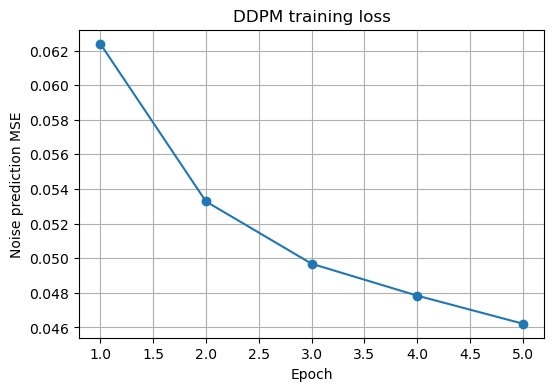

In [14]:
epochs = 5
learning_rate = 2e-4

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
loss_history = []

# 把调度表移到设备上，避免训练时反复复制
beta = beta.to(device)
alpha = alpha.to(device)
alpha_bar = alpha_bar.to(device)

model.train()
for epoch in range(epochs):
    running_loss = 0.0

    for step, (x0, labels) in enumerate(train_loader):
        x0 = x0.to(device)
        y = labels.to(device)

        # 每张图独立随机抽取一个扩散时间步
        t = torch.randint(0, T, (x0.shape[0],), device=device)
        noise = torch.randn_like(x0)

        # 构造带噪图像
        alpha_bar_t = alpha_bar[t].view(-1, 1, 1, 1)
        xt = (
            torch.sqrt(alpha_bar_t) * x0
            + torch.sqrt(1.0 - alpha_bar_t) * noise
        )

        # 预测噪声并计算 MSE
        # predicted_noise = model(xt, t)
        predicted_noise = model(xt, t, y)
        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_history.append(epoch_loss)
    print(f"Epoch {epoch + 1:02d}/{epochs} | loss = {epoch_loss:.5f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Noise prediction MSE")
plt.title("DDPM training loss")
plt.grid(True)
plt.show()

## 7. 反向扩散：从随机噪声生成图片

训练时网络学会了预测噪声。采样时，我们从

\[
x_{T-1}\sim\mathcal N(0,I)
\]

开始，按时间步从大到小反复去噪。

在 DDPM 的参数化下，反向均值可写为：

\[
\mu_\theta(x_t,t)=
\frac{1}{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}
\epsilon_\theta(x_t,t)\right).
\]

采样时加入方差项：

\[
x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\beta_t}z,
\quad z\sim\mathcal N(0,I).
\]

最后一步不再添加随机噪声。下面的实现使用简单的 \(\beta_t\) 方差形式，这是便于入门理解的 DDPM 采样器。

In [15]:
@torch.no_grad()
def sample_ddpm(model, n_samples=16, digit=7):
    model.eval()

    # 从标准高斯噪声开始
    x = torch.randn(n_samples, 1, 28, 28, device=device)

    # 新增：指定要生成的数字
    y = torch.full(
        (n_samples,), digit, device=device, dtype=torch.long
    )

    for t_value in reversed(range(T)):
        t = torch.full((n_samples,), t_value, device=device, dtype=torch.long)

        predicted_noise = model(x, t, y)

        beta_t = beta[t_value]
        alpha_t = alpha[t_value]
        alpha_bar_t = alpha_bar[t_value]

        # DDPM 反向均值
        mean = (1.0 / torch.sqrt(alpha_t)) * (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * predicted_noise
        )

        if t_value > 0:
            z = torch.randn_like(x)
            x = mean + torch.sqrt(beta_t) * z
        else:
            x = mean

    return x.clamp(-1, 1)

## 8. 生成并查看手写数字

训练完成后运行下面的 cell。刚开始生成结果可能比较模糊或不容易辨认，这是正常的；可以增加训练轮数，再比较结果变化。

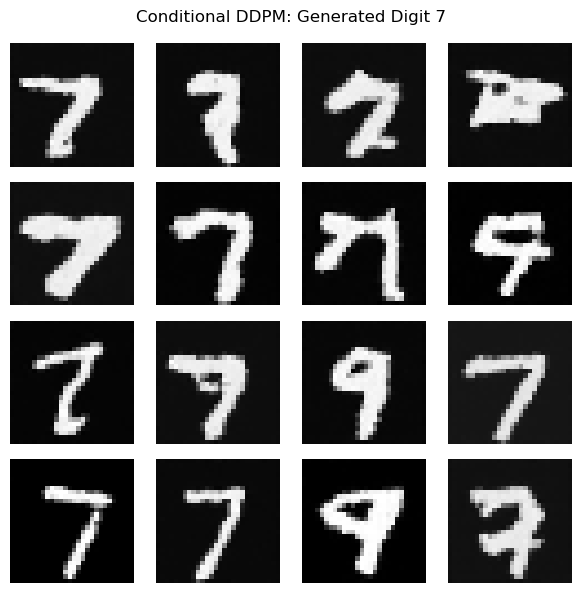

In [17]:
# 指定生成数字 7
digit = 7

generated = sample_ddpm(model, n_samples=16, digit=digit)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    img = (generated[i, 0].cpu() * 0.5 + 0.5).clamp(0, 1)
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle(f"Conditional DDPM: Generated Digit {digit}")
plt.tight_layout()
plt.show()

## 9. 保存与加载模型

`state_dict` 保存的是模型参数。重新加载时，需要先用相同的模型结构实例化模型，再加载参数。

In [18]:
save_path = "mnist_ddpm_unet.pth"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "T": T,
        "loss_history": loss_history,
    },
    save_path,
)
print("Saved to:", os.path.abspath(save_path))

Saved to: /Users/minzhu/Documents/Projects/AI-crash-course/tutorial/mnist_ddpm_unet.pth


In [ ]:
# 演示如何重新加载
checkpoint = torch.load(save_path, map_location=device, weights_only=False)

loaded_model = SimpleUNet().to(device)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

print("Loaded checkpoint. T =", checkpoint["T"])

## 10. 复盘：把数学和代码对应起来

| 数学概念 | Notebook 中的实现 | 作用 |
|---|---|---|
| \(\beta_t\) | `beta` | 每一步的噪声强度 |
| \(\alpha_t=1-\beta_t\) | `alpha` | 每一步保留信号的比例 |
| \(\bar\alpha_t\) | `alpha_bar` | 累积保留的信号比例 |
| \(q(x_t\mid x_0)\) | `q_sample` / 训练中的 `xt` | 直接构造带噪图片 |
| \(\epsilon_\theta(x_t,t)\) | `model(xt, t)` | 预测噪声的 U-Net |
| \(\|\epsilon-\epsilon_\theta\|^2\) | `F.mse_loss(predicted_noise, noise)` | 训练损失 |
| 反向采样公式 | `sample_ddpm` | 从噪声逐步生成图片 |

### 可以继续做的实验

1. 把 `epochs = 5` 改成 `10` 或 `20`，观察生成质量如何变化。
2. 把 `T = 300` 改成 `1000`，比较训练与采样时间。
3. 尝试改变 `base_channels=64`，例如改为 `32` 来加速，或改为 `96` 来增加模型容量（需相应修改实例化方式）。
4. 记录每隔几个 epoch 的生成结果，比较模型如何逐渐学会生成数字。
5. 在理解无条件 DDPM 后，再尝试加入数字类别标签，实现条件扩散模型。

### 常见问题

- **为什么训练时随机选 `t`？** 这样一次训练就能学习不同噪声水平下的去噪任务。
- **为什么网络预测噪声而不是原图？** 这是 DDPM 的常见参数化方式，目标简单稳定，并能用于构造反向更新。
- **为什么采样比一次前向传播慢？** 这个基础 DDPM 需要循环执行 `T` 次网络推理。
- **为什么生成结果不一定很好？** 模型容量、训练轮数、噪声调度和采样方式都会影响生成质量。
- **这里有没有使用预训练模型？** 没有。U-Net 参数从随机初始化开始训练。